In [1]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

# 1. Fetch dataset Automobile dari UCI Repository
automobile = fetch_ucirepo(id=10)
df = pd.concat(
    [automobile.data.features, automobile.data.targets], axis=1
)

# 2. Pemilihan Fitur Utama & Target
features = ['horsepower', 'engine-size', 'curb-weight', 'city-mpg']
X_model = df[features].copy()
y_model = pd.to_numeric(df['price'], errors='coerce')

# 3. Handling Missing Values & Data Type Conversion
for col in features:
  X_model[col] = pd.to_numeric(X_model[col], errors='coerce')
  median_val = X_model[col].median()
  X_model[col] = X_model[col].fillna(median_val)

# 4. Filter Baris Target Valid (Menghapus NaN pada Target)
combined = X_model.copy()
combined['price'] = y_model
combined = combined.dropna()

X_clean = combined[features]
y_clean = combined['price']

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Pembagian Data Latih (80%) dan Data Uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

# 2. Inisialisasi & Training Model (Fitting)
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Prediksi Data Uji & Evaluasi Performa
y_pred = model.predict(X_test)

print('=== HASIL EVALUASI PERFORMA MODEL ===')
print('R-Squared (R2) Score :', r2_score(y_test, y_pred))
print('Root Mean Squared Error (RMSE) :', np.sqrt(mean_squared_error(y_test, y_pred)))

=== HASIL EVALUASI PERFORMA MODEL ===
R-Squared (R2) Score : 0.7635645177510695
Root Mean Squared Error (RMSE) : 5378.393653815795


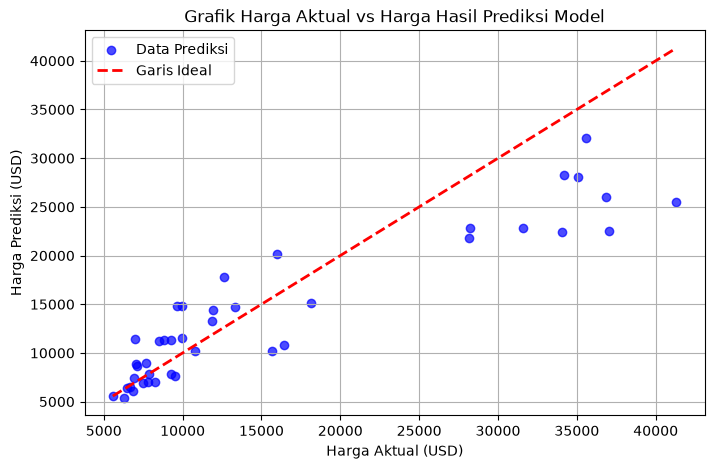

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, label='Data Prediksi')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Garis Ideal',
)
plt.title('Grafik Harga Aktual vs Harga Hasil Prediksi Model')
plt.xlabel('Harga Aktual (USD)')
plt.ylabel('Harga Prediksi (USD)')
plt.legend()
plt.grid(True)
plt.show()

In [4]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from ucimlrepo import fetch_ucirepo

# 1. Load Dataset Automobile dari UCI Repository
automobile = fetch_ucirepo(id=10)
df = pd.concat(
    [automobile.data.features, automobile.data.targets], axis=1
)

# 2. Data Preparation & Cleaning
features = ['horsepower', 'engine-size', 'curb-weight', 'city-mpg']
X_model = df[features].copy()
y_model = pd.to_numeric(df['price'], errors='coerce')

for col in features:
  X_model[col] = pd.to_numeric(X_model[col], errors='coerce')
  X_model[col] = X_model[col].fillna(X_model[col].median())

combined = X_model.copy()
combined['price'] = y_model
combined = combined.dropna()

X_clean = combined[features]
y_clean = combined['price']

# 3. Train Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

# 4. Fitting Model Regresi Linear
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Prediksi & Evaluasi Performa
y_pred = model.predict(X_test)
print('R-Squared (R2 Score)          :', r2_score(y_test, y_pred))
print('Root Mean Squared Error (RMSE):', np.sqrt(mean_squared_error(y_test, y_pred)))

R-Squared (R2 Score)          : 0.7635645177510695
Root Mean Squared Error (RMSE): 5378.393653815795


--> Mengunduh dataset Automobile dari UCI Repository...

             1. PROSES FITTING MODEL            
[INFO] Model Regresi Linier Berhasil Dilatih (Fitted)!
[-] Nilai Intercept (c) : -7836.6942
[-] Nilai Koefisien / Slope (m) per Fitur:
    * horsepower      : 24.0153
    * engine-size     : 83.9032
    * curb-weight     : 3.7583
    * city-mpg        : -80.6639

         2. HASIL EVALUASI PERFORMA MODEL       
[-] R-Squared (R2 Score)          : 0.7636 (76.36%)
[-] Root Mean Squared Error (RMSE): $5,378.39
[-] Mean Absolute Error (MAE)     : $3,782.10

[INFO] Sampel 5 Hasil Prediksi Pertama:
 Harga Aktual (Y Test)  Harga Prediksi (Y Pred)  Selisih / Error
                8249.0                  7005.03          1243.97
               41315.0                 25482.25         15832.75
                6855.0                  6043.31           811.69
                9258.0                  7851.04          1406.96
               11850.0                 13252.87          1402.87


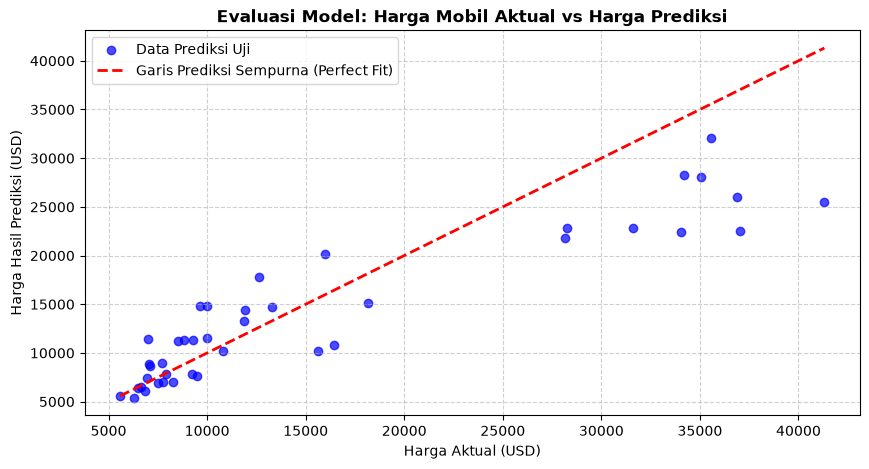

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==============================================================================
# 1. LOAD DATASET DARI UCI REPOSITORY
# ==============================================================================
print("--> Mengunduh dataset Automobile dari UCI Repository...")
automobile = fetch_ucirepo(id=10)
df = pd.concat([automobile.data.features, automobile.data.targets], axis=1)

# ==============================================================================
# 2. PREPROCESSING & CLEANING DATA
# ==============================================================================
features = ['horsepower', 'engine-size', 'curb-weight', 'city-mpg']
X_model = df[features].copy()
y_model = pd.to_numeric(df['price'], errors='coerce')

# Preprocessing fitur numerik (penanganan missing value dengan median)
for col in features:
    X_model[col] = pd.to_numeric(X_model[col], errors='coerce')
    X_model[col] = X_model[col].fillna(X_model[col].median())

# Penggabungan dan pembersihan baris target NaN
combined = X_model.copy()
combined['price'] = y_model
combined = combined.dropna()

X_clean = combined[features]
y_clean = combined['price']

# Split data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

# ==============================================================================
# 3. PROSES FITTING MODEL (TRAINING) & MENAMPILKAN DETAIL
# ==============================================================================
print("\n" + "="*50)
print("             1. PROSES FITTING MODEL            ")
print("="*50)

# Inisialisasi model
model = LinearRegression()

# Fitting Model (Melatih model menggunakan data latih)
model.fit(X_train, y_train)

print("[INFO] Model Regresi Linier Berhasil Dilatih (Fitted)!")
print(f"[-] Nilai Intercept (c) : {model.intercept_:.4f}")
print("[-] Nilai Koefisien / Slope (m) per Fitur:")
for feature_name, coef_val in zip(features, model.coef_):
    print(f"    * {feature_name:<15} : {coef_val:.4f}")

# ==============================================================================
# 4. PREDIKSI DATA UJI & MENAMPILKAN HASIL EVALUASI PERFORMA MODEL
# ==============================================================================
# Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# Menhitung metrik-metrik evaluasi
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("\n" + "="*50)
print("         2. HASIL EVALUASI PERFORMA MODEL       ")
print("="*50)
print(f"[-] R-Squared (R2 Score)          : {r2:.4f} ({r2*100:.2f}%)")
print(f"[-] Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"[-] Mean Absolute Error (MAE)     : ${mae:,.2f}")
print("="*50)

# Menampilkan 5 Sampel Hasil Prediksi vs Nilai Aktual
df_hasil = pd.DataFrame({
    'Harga Aktual (Y Test)': y_test.values[:5],
    'Harga Prediksi (Y Pred)': y_pred[:5],
    'Selisih / Error': np.abs(y_test.values[:5] - y_pred[:5])
})
print("\n[INFO] Sampel 5 Hasil Prediksi Pertama:")
print(df_hasil.round(2).to_string(index=False))

# ==============================================================================
# 5. VISUALISASI HASIL EVALUASI
# ==============================================================================
plt.figure(figsize=(10, 5))

# Scatter Plot Aktual vs Prediksi
plt.scatter(y_test, y_pred, color='blue', alpha=0.7, label='Data Prediksi Uji')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Prediksi Sempurna (Perfect Fit)')

plt.title('Evaluasi Model: Harga Mobil Aktual vs Harga Prediksi', fontsize=12, fontweight='bold')
plt.xlabel('Harga Aktual (USD)')
plt.ylabel('Harga Hasil Prediksi (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

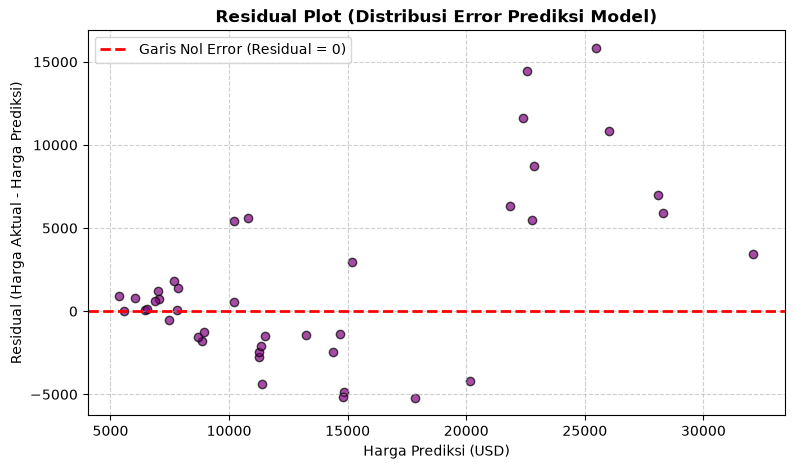

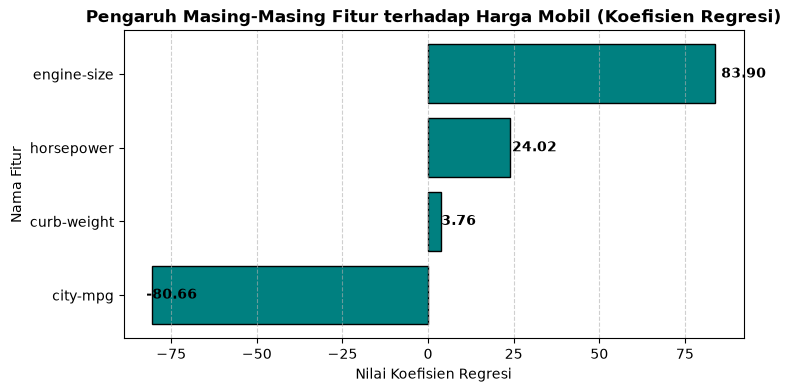

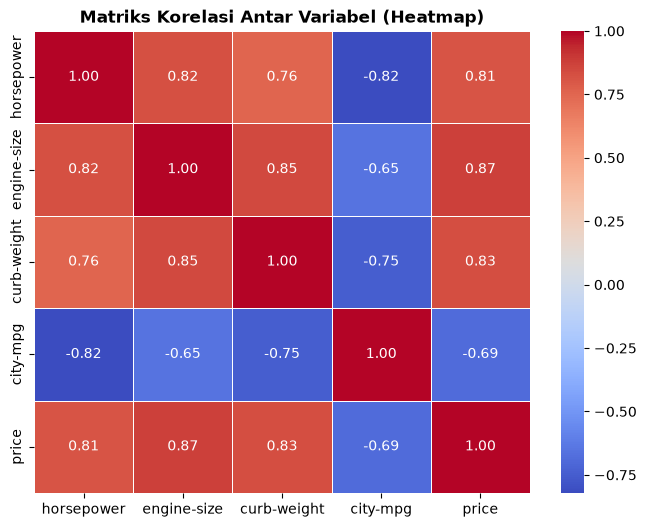

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. RESIDUAL PLOT (Grafik Sebaran Error / Selisih)
# Digunakan untuk mengecek apakah error terdistribusi secara acak (baik untuk regresi)
# ==============================================================================
residuals = y_test - y_pred

plt.figure(figsize=(9, 5))
plt.scatter(y_pred, residuals, color='purple', alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Garis Nol Error (Residual = 0)')
plt.title('Residual Plot (Distribusi Error Prediksi Model)', fontsize=12, fontweight='bold')
plt.xlabel('Harga Prediksi (USD)')
plt.ylabel('Residual (Harga Aktual - Harga Prediksi)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ==============================================================================
# 2. FEATURE IMPORTANCE / BAR CHART KOEFISIEN REGRESI
# Menunjukkan seberapa besar pengaruh positif/negatif tiap fitur terhadap harga
# ==============================================================================
coef_df = pd.DataFrame({
    'Fitur': features,
    'Koefisien (Slope)': model.coef_
}).sort_values(by='Koefisien (Slope)', ascending=True)

plt.figure(figsize=(8, 4))
bars = plt.barh(coef_df['Fitur'], coef_df['Koefisien (Slope)'], color='teal', edgecolor='black')
plt.title('Pengaruh Masing-Masing Fitur terhadap Harga Mobil (Koefisien Regresi)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Koefisien Regresi')
plt.ylabel('Nama Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Memberikan label angka di samping batang grafik
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.02), bar.get_y() + bar.get_height()/2, 
             f'{width:.2f}', va='center', fontsize=10, fontweight='bold')

plt.show()

# ==============================================================================
# 3. CORRELATION HEATMAP (Matriks Korelasi Antar Variabel)
# Menunjukkan hubungan keeratan antar fitur numerik dan target 'price'
# ==============================================================================
plt.figure(figsize=(8, 6))
# Menggabungkan kembali X_clean dan y_clean untuk dihitung korelasinya
corr_data = X_clean.copy()
corr_data['price'] = y_clean

correlation_matrix = corr_data.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Matriks Korelasi Antar Variabel (Heatmap)', fontsize=12, fontweight='bold')
plt.show()

--> Menampilkan Pairplot (Distribusi & Hubungan Antar Variabel)...


<Figure size 1000x1000 with 0 Axes>

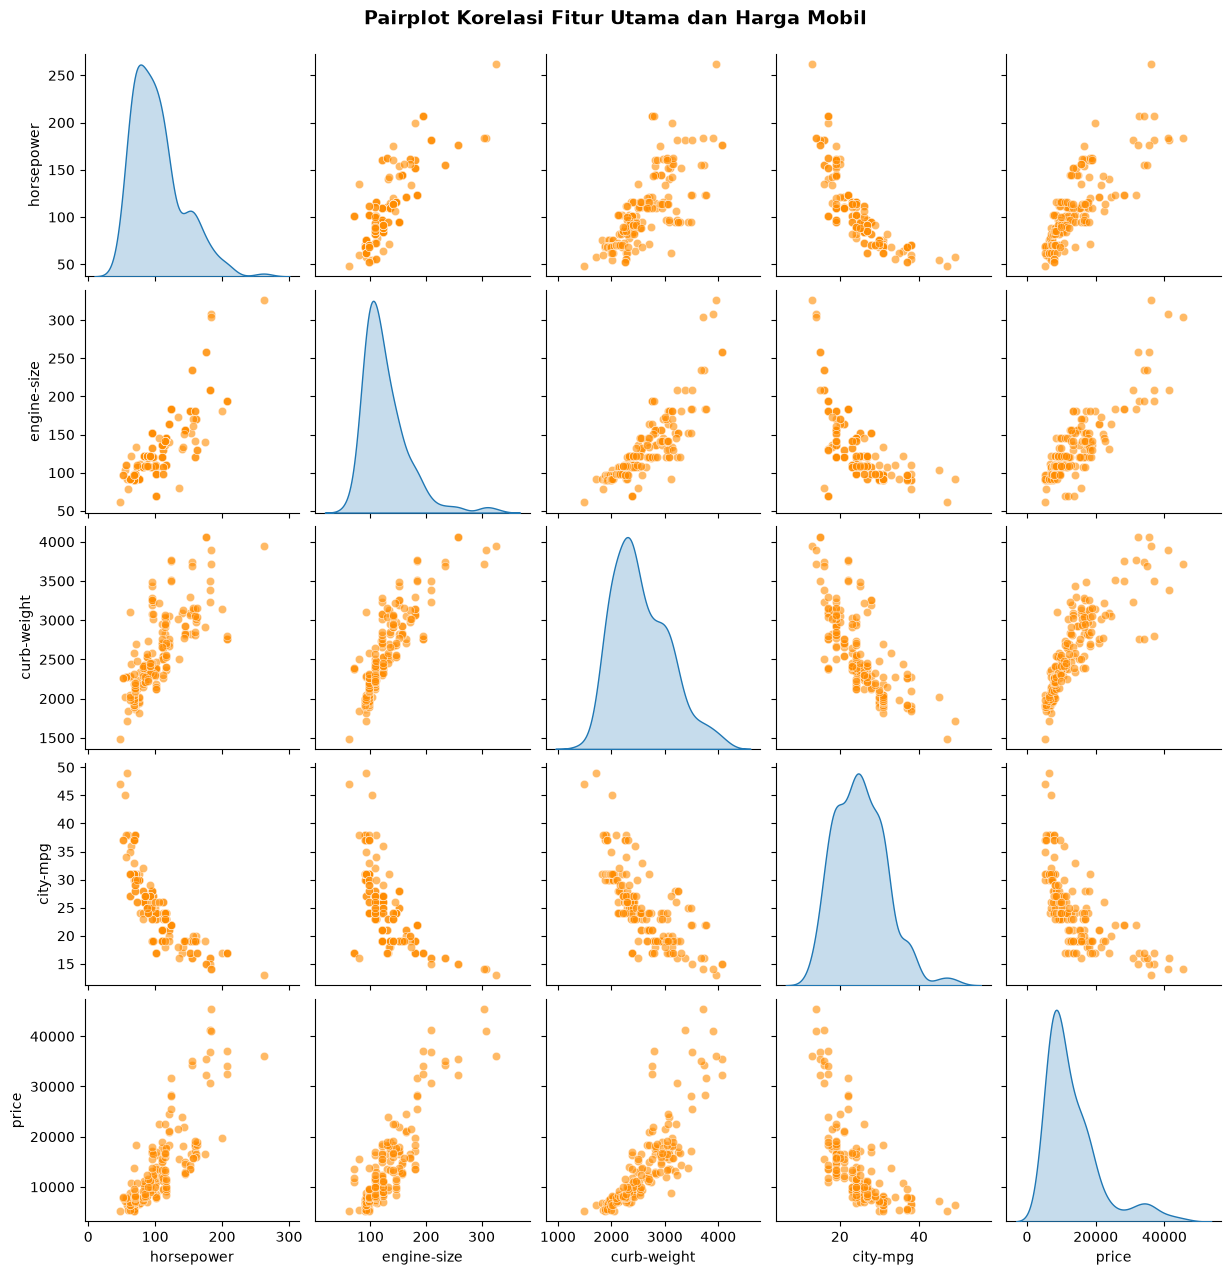

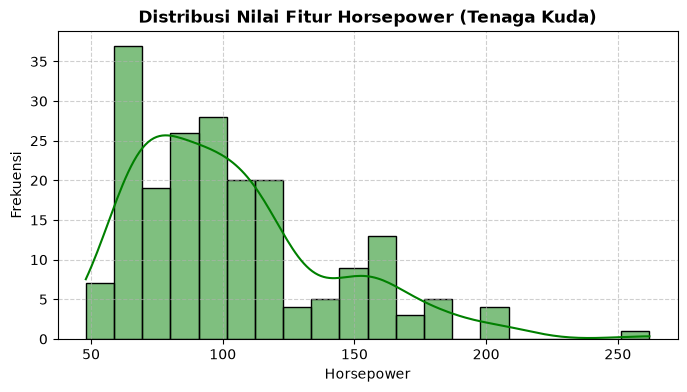

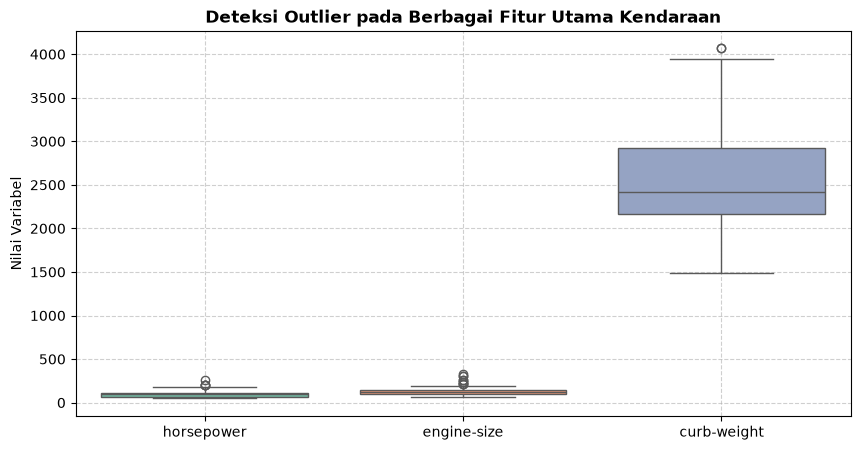

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 4. PAIRPLOT (Eksplorasi Hubungan Antar Semua Fitur Numerik & Target)
# Menampilkan kombinasi scatter plot dan histogram untuk melihat pola data secara menyeluruh
# ==============================================================================
print("--> Menampilkan Pairplot (Distribusi & Hubungan Antar Variabel)...")
plt.figure(figsize=(10, 10))
sns.pairplot(corr_data[['horsepower', 'engine-size', 'curb-weight', 'city-mpg', 'price']], 
             diag_kind='kde', 
             plot_kws={'alpha': 0.6, 'color': 'darkorange'})
plt.suptitle('Pairplot Korelasi Fitur Utama dan Harga Mobil', y=1.02, fontsize=14, fontweight='bold')
plt.show()

# ==============================================================================
# 5. DISTRIBUSI DISTPLOT / HISTOGRAM KERNEL DENSITY ESTIMATION (KDE)
# Untuk melihat bentuk sebaran nilai pada fitur 'horsepower'
# ==============================================================================
plt.figure(figsize=(8, 4))
sns.histplot(X_clean['horsepower'], kde=True, color='green', bins=20)
plt.title('Distribusi Nilai Fitur Horsepower (Tenaga Kuda)', fontsize=12, fontweight='bold')
plt.xlabel('Horsepower')
plt.ylabel('Frekuensi')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ==============================================================================
# 6. BOXPLOT UNTUK MENDETEKSI OUTLIER PADA FITUR-FITUR UTAMA
# Menampilkan sebaran outlier pada fitur horsepower, engine-size, dan curb-weight
# ==============================================================================
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_clean[['horsepower', 'engine-size', 'curb-weight']], palette='Set2')
plt.title('Deteksi Outlier pada Berbagai Fitur Utama Kendaraan', fontsize=12, fontweight='bold')
plt.ylabel('Nilai Variabel')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()